# Projet : Optimisation de l'entraînement d'un Transformer
## Étudiant 1 — Nada : Dataset, Baseline et Learning Rate (version finale)

**Objectif :** préparer le dataset Rotten Tomatoes, entraîner une baseline DistilBERT, puis comparer 4 Learning Rates sur la **précision**, la **convergence** et la **stabilité**.

**Budget :** le projet est limité à 15 entraînements pour 4 étudiants ; la part de l'Étudiant 1 est de **4 entraînements** : 4 Learning Rates × 1 seed (la baseline `2e-5` en fait partie). Chaque entraînement dure environ 1,5 minute, bien sous la limite de 10 minutes.

**Règle :** le meilleur Learning Rate est choisi sur la **Validation**. Le Test n'est affiché qu'à la fin.

**Nouveautés de cette version**
- Évaluation tous les **50 steps** → vraies courbes de convergence et de stabilité (moyenne ± écart-type entre seeds).
- Indicateurs chiffrés : écart meilleur/final, écart-type de la train loss, steps pour atteindre 80 %, divergences.
- Configuration **explicite** (optimizer, scheduler, warmup) + versions des librairies + `README.md` pour les collègues.
- Tableau test sans doublon, avec une référence **TF-IDF + LogReg**.
- Métriques communes (Accuracy, Precision, Recall, F1) pour le protocole de l'Étudiant 4.

## 1. Installation et imports

In [1]:
!pip install -q transformers datasets accelerate scikit-learn pandas matplotlib

In [2]:
import os, gc, json, math, time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import transformers, datasets, sklearn

from IPython.display import display
from datasets import load_dataset, Dataset
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding,
    TrainingArguments, Trainer, pipeline, set_seed
)

print("GPU disponible :", torch.cuda.is_available())
print("transformers :", transformers.__version__, "| datasets :", datasets.__version__, "| torch :", torch.__version__)

GPU disponible : True
transformers : 5.22.1 | datasets : 4.8.5 | torch : 2.14.1+cu130


## 2. Configuration (tout est explicite, pour que les collègues reproduisent la baseline)

In [3]:
MODEL_NAME = "distilbert-base-uncased"

# Budget Étudiant 1 : 4 entraînements (15 pour tout le groupe).
# Les 4 LR couvrent 4 régimes : trop bas, référence, élevé, divergence.
LEARNING_RATES = [1e-6, 2e-5, 1e-4, 5e-4]
SEEDS = [42]
BASELINE_LR = 2e-5

EPOCHS = 3
BATCH_SIZE = 16
MAX_LENGTH = 128
WEIGHT_DECAY = 0.01
OPTIMIZER = "adamw_torch"
SCHEDULER = "linear"
WARMUP_STEPS = 0
EVAL_STEPS = 50

CONV_THR = 0.80          # seuil de val accuracy pour mesurer la vitesse de convergence
DIVERGENCE_ACC = 0.55    # val accuracy finale < 0.55 => modèle effondré (classe unique)

OUTPUT_DIR = "livrables_etudiant1"
os.makedirs(OUTPUT_DIR, exist_ok=True)

LABEL_NAMES = {0: "NEGATIVE", 1: "POSITIVE"}
LABEL2ID = {v: k for k, v in LABEL_NAMES.items()}

## 3. Chargement et préparation du dataset
Rotten Tomatoes possède déjà Train / Validation / Test : on conserve ces splits officiels.

In [4]:
dataset = load_dataset("cornell-movie-review-data/rotten_tomatoes")

train_df = pd.DataFrame(dataset["train"])
val_df = pd.DataFrame(dataset["validation"])
test_df = pd.DataFrame(dataset["test"])

def clean_text(text):
    return " ".join(str(text).split())

train_df["text"] = train_df["text"].apply(clean_text)
val_df["text"] = val_df["text"].apply(clean_text)
test_df["text"] = test_df["text"].apply(clean_text)

train_df = train_df.dropna(subset=["text", "label"])
val_df = val_df.dropna(subset=["text", "label"])
test_df = test_df.dropna(subset=["text", "label"])

print("Train :", len(train_df), "| Validation :", len(val_df), "| Test :", len(test_df))
for name, d in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    print(f"{name:5s}", d["label"].map(LABEL_NAMES).value_counts(normalize=True).round(3).to_dict())

display(train_df.head())

train_df.to_csv(f"{OUTPUT_DIR}/train.csv", index=False)
val_df.to_csv(f"{OUTPUT_DIR}/val.csv", index=False)
test_df.to_csv(f"{OUTPUT_DIR}/test.csv", index=False)

README.md:   0%|          | 0.00/7.46k [00:00<?, ?B/s]

train.parquet: reconstructing file:   0%|          |  0.00B /  699kB            

train.parquet: downloading bytes:           |  0.00B            

validation.parquet: reconstructing file:   0%|          |  0.00B / 90.0kB            

validation.parquet: downloading bytes:           |  0.00B            

test.parquet: reconstructing file:   0%|          |  0.00B / 92.2kB            

... (2 outputs left out)

Generating validation split:   0%|          | 0/1066 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1066 [00:00<?, ? examples/s]

Train : 8530 | Validation : 1066 | Test : 1066
Train {'POSITIVE': 0.5, 'NEGATIVE': 0.5}
Val   {'POSITIVE': 0.5, 'NEGATIVE': 0.5}
Test  {'POSITIVE': 0.5, 'NEGATIVE': 0.5}


,text,label
0,the rock is destined to be the 21st century's ...,1
1,"the gorgeously elaborate continuation of "" the...",1
2,effective but too-tepid biopic,1
3,if you sometimes like to go to the movies to h...,1
4,"emerges as something rare , an issue movie tha...",1


## 4. Référence classique : TF-IDF + régression logistique
Elle permet de mesurer l'apport du fine-tuning d'un Transformer. Son test n'est évalué qu'à la fin.

In [5]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train = tfidf.fit_transform(train_df["text"])
clf = LogisticRegression(max_iter=2000, C=3.0).fit(X_train, train_df["label"])
classic_val_acc = accuracy_score(val_df["label"], clf.predict(tfidf.transform(val_df["text"])))
print(f"TF-IDF + LogReg | Val accuracy : {classic_val_acc:.4f}")

TF-IDF + LogReg | Val accuracy : 0.7467


## 5. Tokenisation avec DistilBERT (padding dynamique)

In [6]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_function(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

train_data = Dataset.from_pandas(train_df[["text", "label"]], preserve_index=False)
val_data = Dataset.from_pandas(val_df[["text", "label"]], preserve_index=False)
test_data = Dataset.from_pandas(test_df[["text", "label"]], preserve_index=False)

train_data = train_data.map(tokenize_function, batched=True, remove_columns=["text"])
val_data = val_data.map(tokenize_function, batched=True, remove_columns=["text"])
test_data = test_data.map(tokenize_function, batched=True, remove_columns=["text"])

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

lens = np.array([len(x) for x in train_data["input_ids"]])
print(f"Longueur en tokens : moyenne {lens.mean():.1f} | p95 {np.percentile(lens, 95):.0f} | max {lens.max()}")
print(f"Textes tronqués à {MAX_LENGTH} tokens : {(lens >= MAX_LENGTH).mean():.2%}")

STEPS_PER_EPOCH = math.ceil(len(train_data) / BATCH_SIZE)
print(f"Steps par epoch : {STEPS_PER_EPOCH} | Steps totaux : {STEPS_PER_EPOCH * EPOCHS}")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/8530 [00:00<?, ? examples/s]

Map:   0%|          | 0/1066 [00:00<?, ? examples/s]

Map:   0%|          | 0/1066 [00:00<?, ? examples/s]

Longueur en tokens : moyenne 27.4 | p95 47 | max 78
Textes tronqués à 128 tokens : 0.00%
Steps par epoch : 534 | Steps totaux : 1602


## 6. Fonctions d'entraînement
L'évaluation se fait tous les 50 steps **et** une dernière fois à la toute fin de l'entraînement (la valeur « finale » est donc bien celle du dernier step).

In [7]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=1)
    return {
        "accuracy": accuracy_score(labels, predictions),
        "f1": f1_score(labels, predictions, average="macro"),
        "precision": precision_score(labels, predictions, average="macro", zero_division=0),
        "recall": recall_score(labels, predictions, average="macro", zero_division=0),
    }


def summarize_history(hist):
    """Indicateurs de convergence et de stabilité à partir du log d'entraînement."""
    ev = hist.dropna(subset=["eval_loss"])
    tr = hist.dropna(subset=["loss"])
    final_acc, best_acc = ev["eval_accuracy"].iloc[-1], ev["eval_accuracy"].max()
    final_loss = ev["eval_loss"].iloc[-1]
    second_half = tr["loss"].iloc[len(tr) // 2:]
    reached = ev.loc[ev["eval_accuracy"] >= CONV_THR, "step"]
    return {
        "val_accuracy": final_acc,
        "best_val_accuracy": best_acc,
        "val_f1": ev["eval_f1"].iloc[-1],
        "val_precision": ev["eval_precision"].iloc[-1],
        "val_recall": ev["eval_recall"].iloc[-1],
        "val_loss": final_loss,
        "gap": best_acc - final_acc,                                      # perte entre le meilleur point et la fin
        "train_loss_std": float(second_half.std()) if len(second_half) > 1 else np.nan,
        "step_to_thr": float(reached.min()) if len(reached) else np.nan,  # vitesse de convergence
        "diverged": bool(final_acc < DIVERGENCE_ACC or not np.isfinite(final_loss)),
    }


ARGS_USED = {}   # valeurs réellement utilisées par Trainer (pour le README)

def train_one_model(learning_rate, seed, save_path=None):
    set_seed(seed)

    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=2, id2label=LABEL_NAMES, label2id=LABEL2ID
    )

    args = TrainingArguments(
        output_dir="./training",
        learning_rate=learning_rate,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=64,
        num_train_epochs=EPOCHS,
        weight_decay=WEIGHT_DECAY,
        optim=OPTIMIZER,
        lr_scheduler_type=SCHEDULER,
        warmup_steps=WARMUP_STEPS,
        eval_strategy="steps",
        eval_steps=EVAL_STEPS,
        logging_strategy="steps",
        logging_steps=EVAL_STEPS,
        save_strategy="no",
        report_to="none",
        disable_tqdm=True,
        fp16=torch.cuda.is_available(),
        seed=seed,
        data_seed=seed,
    )
    ARGS_USED.update({"optim": str(args.optim), "lr_scheduler_type": str(args.lr_scheduler_type),
                      "warmup_steps": args.warmup_steps})

    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_data,
        eval_dataset=val_data,
        processing_class=tokenizer,
        data_collator=data_collator,
        compute_metrics=compute_metrics,
    )

    start = time.time()
    trainer.train()
    duration = time.time() - start

    trainer.evaluate()                                    # évaluation au dernier step
    hist = pd.DataFrame(trainer.state.log_history)        # figé AVANT l'évaluation test
    test_scores = trainer.evaluate(test_data, metric_key_prefix="test")   # stocké, affiché seulement à la fin

    if save_path:
        trainer.save_model(save_path)
        tokenizer.save_pretrained(save_path)

    result = {
        "learning_rate": learning_rate,
        "seed": seed,
        **summarize_history(hist),
        "test_accuracy": test_scores["test_accuracy"],
        "test_f1": test_scores["test_f1"],
        "test_precision": test_scores["test_precision"],
        "test_recall": test_scores["test_recall"],
        "time_seconds": round(duration, 1),
    }

    del trainer, model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result, hist

## 7. Comparaison des Learning Rates (4 entraînements)
La baseline `2e-5` est sauvegardée pour l'inférence. Durée estimée : 6 à 8 minutes sur GPU T4.

In [8]:
baseline_model_path = f"{OUTPUT_DIR}/models/baseline_lr_2e-05"
os.makedirs(f"{OUTPUT_DIR}/models", exist_ok=True)

results, histories = [], {}
n_total = len(LEARNING_RATES) * len(SEEDS)
count = 0

for lr in LEARNING_RATES:
    for seed in SEEDS:
        count += 1
        save = baseline_model_path if (lr == BASELINE_LR and seed == SEEDS[0]) else None
        result, hist = train_one_model(lr, seed, save_path=save)
        results.append(result)
        histories[(lr, seed)] = hist
        flag = " | DIVERGÉ" if result["diverged"] else ""
        print(f"[{count}/{n_total}] LR={lr:.0e} | seed={seed} | Val Acc={result['val_accuracy']:.4f} "
              f"| Val Loss={result['val_loss']:.4f} | {result['time_seconds']} s{flag}")

results_df = pd.DataFrame(results)
results_df.to_csv(f"{OUTPUT_DIR}/resultats_bruts_par_run.csv", index=False)

# Historique complet (courbes) au format long
long_hist = pd.concat(
    [h.assign(learning_rate=lr, seed=s) for (lr, s), h in histories.items()], ignore_index=True
)
long_hist.to_csv(f"{OUTPUT_DIR}/historique_entrainement.csv", index=False)

print("\nNombre d'entraînements :", len(results_df))

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'loss': '0.6941', 'grad_norm': '2.133', 'learning_rate': '9.694e-07', 'epoch': '0.09363'}
{'eval_loss': '0.6941', 'eval_accuracy': '0.4981', 'eval_f1': '0.3685', 'eval_precision': '0.4895', 'eval_recall': '0.4981', 'eval_runtime': '0.57', 'eval_samples_per_second': '1870', 'eval_steps_per_second': '29.82', 'epoch': '0.09363'}
{'loss': '0.6923', 'grad_norm': '1.128', 'learning_rate': '9.382e-07', 'epoch': '0.1873'}
{'eval_loss': '0.6914', 'eval_accuracy': '0.5103', 'eval_f1': '0.3764', 'eval_precision': '0.5732', 'eval_recall': '0.5103', 'eval_runtime': '0.4851', 'eval_samples_per_second': '2198', 'eval_steps_per_second': '35.05', 'epoch': '0.1873'}
{'loss': '0.6913', 'grad_norm': '2.199', 'learning_rate': '9.07e-07', 'epoch': '0.2809'}
{'eval_loss': '0.6878', 'eval_accuracy': '0.5919', 'eval_f1': '0.5442', 'eval_precision': '0.6582', 'eval_recall': '0.5919', 'eval_runtime': '0.5396', 'eval_samples_per_second': '1976', 'eval_steps_per_second': '31.51', 'epoch': '0.2809'}
{'loss': '0.68

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

... (6 outputs left out)

{'loss': '0.5887', 'grad_norm': '6.851', 'learning_rate': '9.7e-05', 'epoch': '0.09363'}
{'eval_loss': '0.4329', 'eval_accuracy': '0.8021', 'eval_f1': '0.8017', 'eval_precision': '0.8042', 'eval_recall': '0.8021', 'eval_runtime': '0.4428', 'eval_samples_per_second': '2408', 'eval_steps_per_second': '38.39', 'epoch': '0.09363'}
{'loss': '0.4924', 'grad_norm': '3.711', 'learning_rate': '9.388e-05', 'epoch': '0.1873'}
{'eval_loss': '0.4763', 'eval_accuracy': '0.7786', 'eval_f1': '0.7735', 'eval_precision': '0.8062', 'eval_recall': '0.7786', 'eval_runtime': '0.5189', 'eval_samples_per_second': '2054', 'eval_steps_per_second': '32.76', 'epoch': '0.1873'}
{'loss': '0.4385', 'grad_norm': '6.781', 'learning_rate': '9.076e-05', 'epoch': '0.2809'}
{'eval_loss': '0.4465', 'eval_accuracy': '0.7833', 'eval_f1': '0.779', 'eval_precision': '0.8073', 'eval_recall': '0.7833', 'eval_runtime': '0.4451', 'eval_samples_per_second': '2395', 'eval_steps_per_second': '38.19', 'epoch': '0.2809'}
{'loss': '0.38

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'loss': '0.7255', 'grad_norm': '2.622', 'learning_rate': '0.0004847', 'epoch': '0.09363'}
{'eval_loss': '0.6933', 'eval_accuracy': '0.5', 'eval_f1': '0.3333', 'eval_precision': '0.25', 'eval_recall': '0.5', 'eval_runtime': '0.437', 'eval_samples_per_second': '2439', 'eval_steps_per_second': '38.9', 'epoch': '0.09363'}
{'loss': '0.7141', 'grad_norm': '1.113', 'learning_rate': '0.0004691', 'epoch': '0.1873'}
{'eval_loss': '0.6936', 'eval_accuracy': '0.5', 'eval_f1': '0.3333', 'eval_precision': '0.25', 'eval_recall': '0.5', 'eval_runtime': '0.4361', 'eval_samples_per_second': '2444', 'eval_steps_per_second': '38.98', 'epoch': '0.1873'}
{'loss': '0.7009', 'grad_norm': '2.174', 'learning_rate': '0.0004535', 'epoch': '0.2809'}
{'eval_loss': '0.6944', 'eval_accuracy': '0.5', 'eval_f1': '0.3333', 'eval_precision': '0.25', 'eval_recall': '0.5', 'eval_runtime': '0.4393', 'eval_samples_per_second': '2427', 'eval_steps_per_second': '38.7', 'epoch': '0.2809'}
{'loss': '0.7002', 'grad_norm': '0.822

## 8. Tableau comparatif (validation) et choix du Learning Rate

In [9]:
def pm(x, nd=4):
    x = pd.Series(x).astype(float)
    return f"{x.mean():.{nd}f} ± {x.std(ddof=1):.{nd}f}" if len(x) > 1 else f"{x.mean():.{nd}f}"

rows = []
for lr, g in results_df.groupby("learning_rate"):
    reached = g["step_to_thr"].dropna()
    rows.append({
        "Learning Rate": f"{lr:.0e}",
        "Val Acc (finale)": pm(g["val_accuracy"]),
        "Val Acc (meilleure)": pm(g["best_val_accuracy"]),
        "Val F1": pm(g["val_f1"]),
        "Val Precision": pm(g["val_precision"]),
        "Val Recall": pm(g["val_recall"]),
        "Val Loss": pm(g["val_loss"]),
        "Écart meilleur-final": pm(g["gap"]),
        "Std train loss (2e moitié)": pm(g["train_loss_std"]),
        f"Steps pour {CONV_THR:.0%}": f"{reached.mean():.0f} ({len(reached)}/{len(g)} runs)" if len(reached) else "jamais atteint",
        "Divergences": f"{int(g['diverged'].sum())}/{len(g)}",
        "Temps moyen (s)": round(g["time_seconds"].mean(), 1),
    })
comparison = pd.DataFrame(rows)
display(comparison)
comparison.to_csv(f"{OUTPUT_DIR}/comparaison_learning_rates.csv", index=False)

val_means = results_df.groupby("learning_rate")["val_accuracy"].mean()
best_lr = val_means.idxmax()
print(f"\nMeilleur Learning Rate (moyenne sur la Validation) : {best_lr:.0e}  ({val_means.max():.4f})")

# Plateau : LR dont l'écart avec le meilleur est inférieur à l'incertitude d'échantillonnage de la validation
p, n_val = val_means.max(), len(val_df)
se_val = math.sqrt(p * (1 - p) / n_val)
plateau = [lr for lr in val_means.index if val_means.max() - val_means[lr] <= se_val]
print(f"Incertitude de la validation (1 écart-type) : ±{se_val:.3f}")
print("Learning Rates statistiquement indiscernables du meilleur (plateau) :", ", ".join(f"{lr:.0e}" for lr in plateau))
if len(SEEDS) == 1:
    print("Un seul seed par LR : des écarts inférieurs à ±1 point ne sont pas significatifs, à mentionner dans le rapport.")

,Learning Rate,Val Acc (finale),Val Acc (meilleure),Val F1,Val Precision,Val Recall,Val Loss,Écart meilleur-final,Std train loss (2e moitié),Steps pour 80%,Divergences,Temps moyen (s)
0,1e-06,0.7833,0.7899,0.7830,0.7850,0.7833,0.4957,0.0066,0.0264,jamais atteint,0/1,113.9
1,2e-05,0.8499,0.8546,0.8499,0.8500,0.8499,0.4985,0.0047,0.0541,150 (1/1 runs),0/1,100.9
2,1e-04,0.8368,0.8443,0.8367,0.8373,0.8368,0.7707,0.0075,0.0740,50 (1/1 runs),0/1,101.5
3,5e-04,0.5000,0.5000,0.3333,0.2500,0.5000,0.6931,0.0000,0.0005,jamais atteint,1/1,109.6



Meilleur Learning Rate (moyenne sur la Validation) : 2e-05  (0.8499)
Incertitude de la validation (1 écart-type) : ±0.011
Learning Rates statistiquement indiscernables du meilleur (plateau) : 2e-05
Un seul seed par LR : des écarts inférieurs à ±1 point ne sont pas significatifs, à mentionner dans le rapport.


## 9. Courbes de convergence et de stabilité
Avec un seul seed il n'y a pas de bande d'écart-type : la stabilité se lit sur la forme des courbes (oscillations de la train loss, écart meilleur/final).

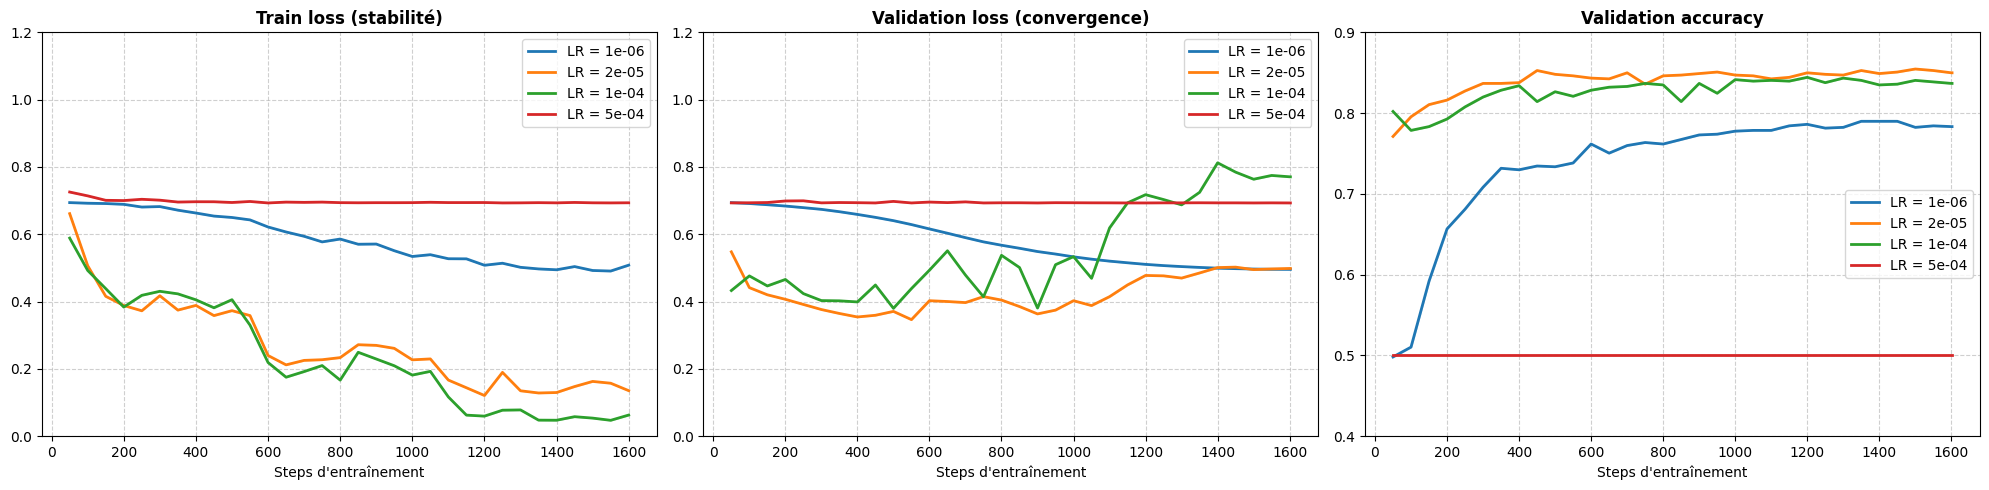

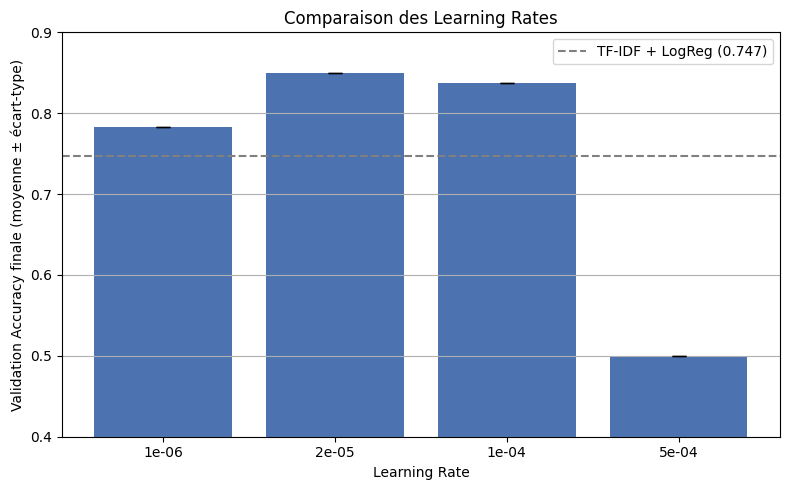

In [10]:
def mean_curve(lr, col):
    series = []
    for (l, s), h in histories.items():
        if l == lr:
            d = h.dropna(subset=[col]).set_index("step")[col]
            series.append(d[~d.index.duplicated()])
    m = pd.concat(series, axis=1)
    return m.index.values, m.mean(axis=1).values, m.std(axis=1).fillna(0).values

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
panels = [
    ("loss", "Train loss (stabilité)", (0, 1.2)),
    ("eval_loss", "Validation loss (convergence)", (0, 1.2)),
    ("eval_accuracy", "Validation accuracy", (0.4, 0.9)),
]
for ax, (col, title, ylim) in zip(axes, panels):
    for k, lr in enumerate(LEARNING_RATES):
        x, m, s = mean_curve(lr, col)
        ax.plot(x, m, linewidth=2, color=plt.cm.tab10(k), label=f"LR = {lr:.0e}")
        ax.fill_between(x, m - s, m + s, alpha=0.15, color=plt.cm.tab10(k))
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Steps d'entraînement")
    ax.set_ylim(*ylim)
    ax.grid(True, linestyle="--", alpha=0.6)
    ax.legend()
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/courbes_convergence_lr.png", dpi=300)
plt.show()

g = results_df.groupby("learning_rate")["val_accuracy"]
plt.figure(figsize=(8, 5))
plt.bar([f"{lr:.0e}" for lr in g.mean().index], g.mean().values,
        yerr=g.std(ddof=1).fillna(0).values, capsize=5, color="#4C72B0")
plt.axhline(classic_val_acc, color="gray", linestyle="--", label=f"TF-IDF + LogReg ({classic_val_acc:.3f})")
plt.ylim(0.4, 0.9)
plt.xlabel("Learning Rate")
plt.ylabel("Validation Accuracy finale (moyenne ± écart-type)")
plt.title("Comparaison des Learning Rates")
plt.legend()
plt.grid(axis="y")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/comparaison_learning_rates.png", dpi=300)
plt.show()

## 10. Évaluation finale sur le Test
Le Test n'est regardé qu'ici, après le choix sur la Validation. Avec 1066 exemples, l'incertitude d'échantillonnage est d'environ ±2 points (IC 95 %).

In [11]:
def ci95(p, n):
    return 1.96 * math.sqrt(p * (1 - p) / n)

n_test = len(test_df)
classic_test_acc = accuracy_score(test_df["label"], clf.predict(tfidf.transform(test_df["text"])))

rows = [{
    "Modèle": "TF-IDF + LogReg (référence)",
    "Test Accuracy": f"{classic_test_acc:.4f}",
    "Test F1": "-",
    "Test Precision": "-",
    "Test Recall": "-",
}]
base = results_df[results_df.learning_rate == BASELINE_LR]
label_base = f"DistilBERT baseline ({BASELINE_LR:.0e})" + (" = meilleur LR" if best_lr == BASELINE_LR else "")
rows.append({"Modèle": label_base, "Test Accuracy": pm(base["test_accuracy"]), "Test F1": pm(base["test_f1"]),
             "Test Precision": pm(base["test_precision"]), "Test Recall": pm(base["test_recall"])})
if best_lr != BASELINE_LR:
    best = results_df[results_df.learning_rate == best_lr]
    rows.append({"Modèle": f"DistilBERT meilleur LR ({best_lr:.0e})",
                 "Test Accuracy": pm(best["test_accuracy"]), "Test F1": pm(best["test_f1"]),
                 "Test Precision": pm(best["test_precision"]), "Test Recall": pm(best["test_recall"])})

final_results = pd.DataFrame(rows)
display(final_results)
final_results.to_csv(f"{OUTPUT_DIR}/resultats_test_finaux.csv", index=False)

p_base = base["test_accuracy"].mean()
print(f"Incertitude d'échantillonnage du test : ±{ci95(p_base, n_test):.3f} (IC 95 %) → "
      "des écarts plus petits que cela ne sont pas significatifs.")

,Modèle,Test Accuracy,Test F1,Test Precision,Test Recall
0,TF-IDF + LogReg (référence),0.7908,-,-,-
1,DistilBERT baseline (2e-05) = meilleur LR,0.8443,0.8443,0.8444,0.8443


Incertitude d'échantillonnage du test : ±0.022 (IC 95 %) → des écarts plus petits que cela ne sont pas significatifs.


## 11. Tester le modèle baseline sur quelques phrases

In [12]:
sentiment_model = pipeline(
    "sentiment-analysis",
    model=baseline_model_path,
    tokenizer=baseline_model_path,
    device=0 if torch.cuda.is_available() else -1,
)

examples = [
    "This movie was amazing and very enjoyable.",
    "The film was boring and disappointing.",
    "The cinematography is decent, though the script lacks originality.",
]
for sentence in examples:
    print(sentence)
    print(sentiment_model(sentence))
    print()

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

This movie was amazing and very enjoyable.
[{'label': 'POSITIVE', 'score': 0.9960820078849792}]

The film was boring and disappointing.
[{'label': 'NEGATIVE', 'score': 0.9959767460823059}]

The cinematography is decent, though the script lacks originality.
[{'label': 'POSITIVE', 'score': 0.9405897259712219}]



## 12. Sauvegarde des résultats et README pour les collègues

In [ ]:
import shutil

ENV = {
    "transformers": transformers.__version__, "datasets": datasets.__version__,
    "torch": torch.__version__, "sklearn": sklearn.__version__,
}
CONFIG = {
    "model": MODEL_NAME, "epochs": EPOCHS, "batch_size": BATCH_SIZE, "max_length": MAX_LENGTH,
    "weight_decay": WEIGHT_DECAY, "optimizer": ARGS_USED["optim"], "scheduler": ARGS_USED["lr_scheduler_type"],
    "warmup_steps": ARGS_USED["warmup_steps"], "fp16": torch.cuda.is_available(),
    "baseline_lr": BASELINE_LR, "seeds": SEEDS, "eval_steps": EVAL_STEPS,
    "splits": "officiels Rotten Tomatoes (8530 / 1066 / 1066)", "versions": ENV,
}
with open(f"{OUTPUT_DIR}/config_et_versions.json", "w", encoding="utf-8") as f:
    json.dump(CONFIG, f, indent=2, ensure_ascii=False)

b = results_df[results_df.learning_rate == BASELINE_LR]
readme = f"""# Livrables Étudiant 1 (Nada) : Dataset, Baseline et Learning Rate

## Données
`train.csv`, `val.csv`, `test.csv` : splits officiels de Rotten Tomatoes ({len(train_df)} / {len(val_df)} / {len(test_df)}), texte nettoyé (espaces normalisés).
À utiliser tels quels par tout le groupe pour que les résultats soient comparables.

## Configuration de la baseline (à reproduire à l'identique)
- Modèle : {MODEL_NAME}, max_length {MAX_LENGTH} (padding dynamique)
- Epochs : {EPOCHS}, batch size : {BATCH_SIZE}, weight decay : {WEIGHT_DECAY}
- Optimizer : {ARGS_USED['optim']}, scheduler : {ARGS_USED['lr_scheduler_type']}, warmup steps : {ARGS_USED['warmup_steps']}
- Learning rate de référence : {BASELINE_LR:.0e}
- Seeds : {SEEDS}
- Versions : transformers {ENV['transformers']}, datasets {ENV['datasets']}, torch {ENV['torch']}

## Résultats de référence
- Baseline (LR {BASELINE_LR:.0e}) : Val Acc {pm(b['val_accuracy'])} | Test Acc {pm(b['test_accuracy'])} (seed(s) : {SEEDS})
- TF-IDF + LogReg : Val {classic_val_acc:.4f} | Test {classic_test_acc:.4f}
- Meilleur LR sur la validation : {best_lr:.0e} ; plateau : {", ".join(f"{lr:.0e}" for lr in plateau)}
- LR 5e-4 : effondrement du modèle (accuracy 0.50, une seule classe prédite)

## Recommandations
- Garder LR = {BASELINE_LR:.0e} comme référence dans les autres expériences.
- Ne pas dépasser 1e-4 (divergence à 5e-4).
- Pour Fatima : la baseline utilise un scheduler linéaire et un warmup de 0 step (point de comparaison pour Warmup/Scheduler).
- Pour Aya : la baseline utilise AdamW et un batch size de 16.
- Incertitude de la validation : environ ±1 point, du test : environ ±2 points. Les petits écarts ne sont pas significatifs.

## Fichiers
`resultats_bruts_par_run.csv`, `comparaison_learning_rates.csv`, `historique_entrainement.csv` (courbes),
`resultats_test_finaux.csv`, `courbes_convergence_lr.png`, `comparaison_learning_rates.png`,
`config_et_versions.json`, `models/baseline_lr_2e-05` (modèle baseline).
"""
with open(f"{OUTPUT_DIR}/README.md", "w", encoding="utf-8") as f:
    f.write(readme)

archive_path = shutil.make_archive("Livrables_Etudiant1_Nada", "zip", OUTPUT_DIR)
print("Archive créée :", archive_path)
print("Fichiers disponibles :", sorted(os.listdir(OUTPUT_DIR)))

try:
    from google.colab import files
    files.download(archive_path)
except ImportError:
    print("Télécharge l'archive depuis le dossier de travail.")